# Kaggle · So sánh YOLO11m COCO pretrained vs YOLO11m fine-tuned VisDrone

**Chỉ đánh giá, KHÔNG train lại.** Hai model chạy trên **cùng một tập DET test-dev**, cùng `imgsz`, cùng tham số NMS và cùng chính sách đánh giá.

- Model A: `yolo11m.pt` COCO-pretrained (80 lớp), chưa fine-tune VisDrone.
- Model B: `best.pt` trong Kaggle Dataset artifacts của lần train YOLO11m trên DET (10 lớp VisDrone).
- Không dùng trực tiếp `YOLO('yolo11m.pt').val(data=visdrone.yaml)` để đối chiếu mAP vì class IDs của COCO và VisDrone không trùng nhau. Notebook này quy về **6 nhóm tương ứng**: `person` (pedestrian + people), `bicycle`, `car` (car + van), `truck`, `bus`, `motorcycle` (motor). Hai nhóm `tricycle`, `awning-tricycle` và các vùng ignored không được tính vào GT và được hạn chế ảnh hưởng tới FP.
- mAP ghi trong notebook là **custom 6-class COCO-style mAP**, **KHÔNG** phải mAP chính thức 10 lớp VisDrone và không được so trực tiếp với chỉ số trong `validation_metrics.json` của run training.

**Kaggle Add Input:** 

(1) `tiendq/visdrone-mot-det-converted`

(2) Dataset chứa `T1_yolo11m_640_det/weights/best.pt`. Bật GPU, bật Internet (chỉ để tải `yolo11m.pt` nếu chưa có).

In [ ]:
from pathlib import Path
import os, sys, json, time, random, shutil, subprocess, platform, zipfile
from datetime import datetime, timezone

# ===================== CẤU HÌNH =====================
DATASET_ROOT = Path('/kaggle/input/datasets/tiendq/visdrone-mot-det-converted/uav_tracking_mot_det')
BEST_PT = Path('/kaggle/input/datasets/tiendq/result-train-det-yolo11m-80e/T1_yolo11m_640_det_artifacts/T1_yolo11m_640_det/weights/best.pt')
BASE_PT = 'yolo11m.pt'  # tự tải pretrained COCO 80 lớp (khi bật Internet)
SPLIT = 'test-dev'           # 'val' hoặc 'test-dev' 
MAX_IMAGES = None        # None = toàn bộ 548 DET val hoặc 1610 DET test-dev
SEED = 0
IMGSZ = 640
DEVICE = 0
BATCH = 8
CONF_EVAL = 0.001     # COCO AP tính trên nhiều ngưỡng confidence
CONF_VIS = 0.25       # chỉ dùng cho ảnh minh họa
IOU_NMS = 0.7
MAX_DET = 1000
N_EXAMPLES = 6

assert SPLIT in ('val','test-dev')
assert MAX_IMAGES is None or MAX_IMAGES > 0
WORK = Path('/kaggle/working')
OUT = WORK / f'compare_yolo11m_det_{SPLIT}_{MAX_IMAGES or "all"}'
OUT.mkdir(parents=True,exist_ok=True)
print('Experiment:',OUT)

Experiment: /kaggle/working/compare_yolo11m_det_test-dev_all


## 1. Môi trường và tìm checkpoint

In [2]:
subprocess.run([sys.executable,'-m','pip','install','-q','ultralytics>=8.3,<9','pycocotools','pandas','matplotlib','Pillow'], check=True)
import numpy as np, pandas as pd, torch, ultralytics
from ultralytics import YOLO
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

if not (DATASET_ROOT/'data'/'processed').is_dir():
    options = [p for p in Path('/kaggle/input').glob('*/uav_tracking_mot_det') if (p/'data'/'processed').is_dir()]
    options += [p.parent for p in Path('/kaggle/input').glob('*/data') if (p/'processed').is_dir()]
    assert len(options) == 1, f'Không xác định được bundle VisDrone. Candidates: {options}'
    DATASET_ROOT = options[0]

if BEST_PT is None:
    candidates = []
    for inp in Path('/kaggle/input').iterdir():
        if not inp.is_dir() or 'visdrone-mot-det-converted' in inp.name.lower():
            continue
        candidates.extend(inp.glob('T1_yolo11m_640_det/weights/best.pt'))
        candidates.extend(inp.glob('*/T1_yolo11m_640_det/weights/best.pt'))
        candidates.extend(inp.glob('*/weights/best.pt'))
    candidates = list(dict.fromkeys(candidates))
    assert len(candidates) == 1, (
        'Không tìm thấy đúng 1 best.pt. Bạn cần Add Input Kaggle Dataset chứa model; '
        f'hoặc chỉ định BEST_PT bằng đường dẫn thủ công. Candidates: {candidates}'
    )
    BEST_PT = candidates[0]
else:
    BEST_PT = Path(BEST_PT)
assert BEST_PT.is_file(), BEST_PT
assert torch.cuda.is_available(), 'Bật GPU trong Kaggle Notebook Settings trước khi chạy.'
print('Converted dataset:', DATASET_ROOT)
print('Fine-tuned checkpoint:', BEST_PT)
print('GPU:',torch.cuda.get_device_name(0),'| Ultralytics',ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Converted dataset: /kaggle/input/datasets/tiendq/visdrone-mot-det-converted/uav_tracking_mot_det
Fine-tuned checkpoint: /kaggle/input/datasets/tiendq/result-train-det-yolo11m-80e/T1_yolo11m_640_det_artifacts/T1_yolo11m_640_det/weights/best.pt
GPU: Tesla T4 | Ultralytics 8.4.198


## 2. Chọn đúng cùng ảnh và xây GT chung sáu nhóm

Đọc `data/processed/coco_det/val.json` (hoặc `test-dev.json`) **trực tiếp**; `images[].file_name` đã là đường dẫn tương đối tới `data/raw/`. 

**Mapping GT:** VisDrone `pedestrian, people → person`; `car, van → car`; `bicycle, truck, bus, motor → nhóm tương ứng`. Loại `tricycle` và `awning-tricycle` khỏi GT chung. Prediction phủ phần lớn vùng ignored hoặc đối tượng loại trừ được bỏ qua khi tính FP. Đây là một phép thử đối chiếu sáu nhóm, không phải benchmark VisDrone chuẩn.

In [3]:
# ID nhóm dùng chung (1-based) để COCOeval làm việc
COMMON_NAMES = {1:'person',2:'bicycle',3:'car',4:'truck',5:'bus',6:'motorcycle'}
VIS_GT_MAP = {1:1,2:1,3:2,4:3,5:3,6:4,9:5,10:6}  # original VisDrone category IDs
VIS_EXCLUDED = {7,8}
COCO_NAME_MAP = {v:k for k,v in COMMON_NAMES.items()}
FINETUNE_NAMES = ['pedestrian','people','bicycle','car','van','truck','tricycle','awning-tricycle','bus','motor']
ANN_FILE = DATASET_ROOT/'data'/'processed'/'coco_det'/f'{SPLIT}.json'
assert ANN_FILE.is_file(), f'Missing {ANN_FILE}'
raw = json.loads(ANN_FILE.read_text(encoding='utf-8'))
all_images = sorted(raw['images'],key=lambda x:x['id'])
if MAX_IMAGES is not None and MAX_IMAGES < len(all_images):
    chosen = sorted(random.Random(SEED).sample(all_images,MAX_IMAGES),key=lambda x:x['id'])
else:
    chosen=all_images
image_ids = {i['id'] for i in chosen}
source_images = {i['id']:i for i in chosen}
IMG_PATH = {i['id']:DATASET_ROOT/'data'/'raw'/i['file_name'] for i in chosen}
missing = [str(p) for p in IMG_PATH.values() if not p.is_file()]
assert not missing, f'Không tìm thấy {len(missing)} ảnh raw. Ví dụ: {missing[:3]}'

# Chỉ giữ GT của 6 nhóm chung, map về 6 category IDs mới.
gt_anns=[]
excluded_by_image={i:[] for i in image_ids}
for a in raw['annotations']:
    iid=a['image_id']
    if iid not in image_ids: continue
    orig_cat=int(a['category_id'])
    if orig_cat in VIS_GT_MAP:
        new_a=dict(a)
        new_a['category_id']=VIS_GT_MAP[orig_cat]
        gt_anns.append(new_a)
    elif orig_cat in VIS_EXCLUDED:
        excluded_by_image[iid].append(a['bbox'])
for ign in raw.get('ignored_regions',[]):
    if ign['image_id'] in image_ids:
        excluded_by_image[ign['image_id']].append(ign['bbox'])

gt_dataset={'info':{'description':'VisDrone DET common 6-class comparison'},
            'images':chosen,'annotations':gt_anns,
            'categories':[{'id':c,'name':n,'supercategory':'common'} for c,n in COMMON_NAMES.items()]}
(GT_FILE:=OUT/'gt_common6.json').write_text(json.dumps(gt_dataset),encoding='utf-8')
coco_gt=COCO(str(GT_FILE))
print(f'DET {SPLIT}: {len(chosen):,}/{len(all_images):,} ảnh | {len(gt_anns):,} GT sáu nhóm')
print('GT/class:',{name:sum(a['category_id']==cat for a in gt_anns) for cat,name in COMMON_NAMES.items()})

loading annotations into memory...
Done (t=0.20s)
creating index...
index created!
DET test-dev: 1,610/1,610 ảnh | 73,973 GT sáu nhóm
GT/class: {'person': 27382, 'bicycle': 1302, 'car': 33845, 'truck': 2659, 'bus': 2940, 'motorcycle': 5845}


## 3. Chạy suy luận cả hai mô hình

Cùng ảnh, `imgsz=640`, `conf=0.001`, `iou=0.7`, `max_det=1000`. Không dùng `YOLO.val` mặc định cho model pretrained COCO vì class ID mismatch. Cùng bộ dự đoán sẽ được đánh giá bằng một hàm COCOeval.

In [4]:
base_model = YOLO(BASE_PT)
fine_model = YOLO(str(BEST_PT))
base_names={int(k):str(v) for k,v in base_model.names.items()}
fine_names={int(k):str(v) for k,v in fine_model.names.items()}
assert len(base_names)==80 and base_names.get(0)=='person', f'Pretrained không phải COCO80: {base_names}'
assert [fine_names.get(i) for i in range(10)]==FINETUNE_NAMES, (
    f'Checkpoint fine-tuned không đúng thứ tự 10 lớp VisDrone: {fine_names}')
BASE_MAP={i:COCO_NAME_MAP[name] for i,name in base_names.items() if name in COCO_NAME_MAP}
FINE_MAP={i:VIS_GT_MAP[i+1] for i in range(10) if i+1 in VIS_GT_MAP}
print('Pretrained COCO mapping:',{base_names[i]:v for i,v in BASE_MAP.items()})
print('Fine-tuned mapping:',{fine_names[i]:v for i,v in FINE_MAP.items()})

def intersection_over_pred(pbox, xbox):
    # pbox, xbox: xywh
    px,py,pw,ph=pbox; x,y,w,h=xbox
    ix=max(0,min(px+pw,x+w)-max(px,x))
    iy=max(0,min(py+ph,y+h)-max(py,y))
    return ix*iy/max(pw*ph,1e-9)

def inference(model, mapping, tag):
    all_dets=[]
    t0=time.time()
    ids=list(IMG_PATH)
    for start in range(0,len(ids),BATCH):
        batch_ids=ids[start:start+BATCH]
        res=model.predict([str(IMG_PATH[i]) for i in batch_ids], imgsz=IMGSZ,
            conf=CONF_EVAL, iou=IOU_NMS, max_det=MAX_DET, device=DEVICE,
            verbose=False, rect=False)
        assert len(res)==len(batch_ids)
        for iid,r in zip(batch_ids,res):
            if r.boxes is None: continue
            xyxy=r.boxes.xyxy.cpu().numpy()
            classes=r.boxes.cls.cpu().numpy().astype(int)
            confs=r.boxes.conf.cpu().numpy()
            exclusions=excluded_by_image[iid]
            for bb,cls,score in zip(xyxy,classes,confs):
                if cls not in mapping: continue
                x1,y1,x2,y2=map(float,bb)
                bbox=[x1,y1,max(0,x2-x1),max(0,y2-y1)]
                if any(intersection_over_pred(bbox,ex)>=0.5 for ex in exclusions):
                    continue
                all_dets.append({'image_id':int(iid),'category_id':int(mapping[cls]),
                    'bbox':bbox,'score':float(score)})
        if ((start//BATCH)%10==0) or (start+BATCH>=len(ids)):
            print(f'{tag}: {min(start+BATCH,len(ids)):,}/{len(ids):,} images',flush=True)
    elapsed=time.time()-t0
    (OUT/f'predictions_{tag}.json').write_text(json.dumps(all_dets),encoding='utf-8')
    print(f'{tag}: {len(all_dets):,} detections | {elapsed:.1f}s')
    return all_dets,elapsed

base_dets,base_sec=inference(base_model,BASE_MAP,'pretrained')
del base_model
if torch.cuda.is_available(): torch.cuda.empty_cache()
fine_dets,fine_sec=inference(fine_model,FINE_MAP,'finetuned')
del fine_model
if torch.cuda.is_available(): torch.cuda.empty_cache()

Pretrained COCO mapping: {'person': 1, 'bicycle': 2, 'car': 3, 'motorcycle': 6, 'bus': 5, 'truck': 4}
Fine-tuned mapping: {'pedestrian': 1, 'people': 1, 'bicycle': 2, 'car': 3, 'van': 3, 'truck': 4, 'bus': 5, 'motor': 6}
pretrained: 8/1,610 images
pretrained: 88/1,610 images
pretrained: 168/1,610 images
pretrained: 248/1,610 images
pretrained: 328/1,610 images
pretrained: 408/1,610 images
pretrained: 488/1,610 images
pretrained: 568/1,610 images
pretrained: 648/1,610 images
pretrained: 728/1,610 images
pretrained: 808/1,610 images
pretrained: 888/1,610 images
pretrained: 968/1,610 images
pretrained: 1,048/1,610 images
pretrained: 1,128/1,610 images
pretrained: 1,208/1,610 images
pretrained: 1,288/1,610 images
pretrained: 1,368/1,610 images
pretrained: 1,448/1,610 images
pretrained: 1,528/1,610 images
pretrained: 1,608/1,610 images
pretrained: 1,610/1,610 images
pretrained: 292,140 detections | 81.2s
finetuned: 8/1,610 images
finetuned: 88/1,610 images
finetuned: 168/1,610 images
finetu

## 4. COCOeval: evaluate → accumulate → precision 


Loading and preparing results...
DONE (t=0.83s)
creating index...
index created!
[COCO pretrained] COCOeval: evaluate -> accumulate (maxDets=[1, 10, 1000])
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=103.32s).
Accumulating evaluation results...
DONE (t=2.63s).
COCO pretrained (maxDets=1000): mAP50-95=0.0861, mAP50=0.1469, AP_small=0.0285, AR1000=0.1631
Loading and preparing results...
DONE (t=1.95s)
creating index...
index created!
[VisDrone fine-tuned] COCOeval: evaluate -> accumulate (maxDets=[1, 10, 1000])
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=204.24s).
Accumulating evaluation results...
DONE (t=4.30s).
VisDrone fine-tuned (maxDets=1000): mAP50-95=0.2605, mAP50=0.4397, AP_small=0.1310, AR1000=0.3528


,model,mAP50_95,mAP50,AP_small,AR1000,n_images,seconds,img_per_sec
0,COCO pretrained,0.086070,0.146860,0.028507,0.163085,1610,81.19,19.83
1,VisDrone fine-tuned,0.260547,0.439685,0.130962,0.352809,1610,65.97,24.41


,class,COCO_pretrained,VisDrone_finetuned,delta
0,person,0.062714,0.131219,0.068505
1,bicycle,0.022173,0.056243,0.034070
2,car,0.250459,0.514622,0.264163
3,truck,0.065553,0.294675,0.229123
4,bus,0.097154,0.411516,0.314362
5,motorcycle,0.018365,0.155004,0.136639


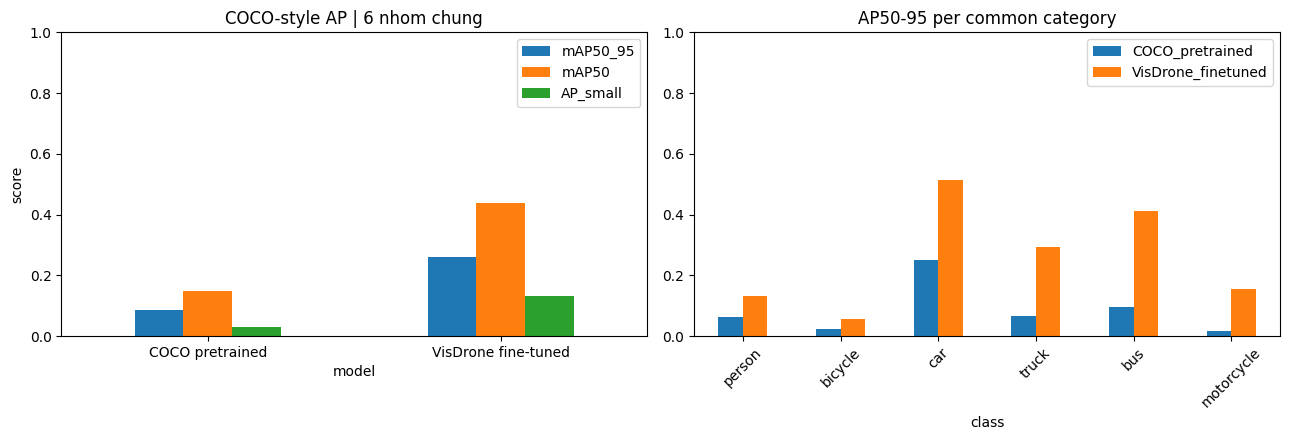

In [5]:
def evaluate(name,detections,seconds):
    if detections:
        coco_pred=coco_gt.loadRes(detections)
    else:
        coco_pred=COCO();coco_pred.dataset={'info':{},'images':chosen,'categories':gt_dataset['categories'],'annotations':[]};coco_pred.createIndex()
    evaluator=COCOeval(coco_gt,coco_pred,'bbox')
    evaluator.params.imgIds=sorted(image_ids)
    evaluator.params.catIds=sorted(COMMON_NAMES)
    evaluator.params.maxDets=[1,10,1000]
    # Required steps: evaluate() fills evalImgs; accumulate() creates eval["precision"].
    # Do NOT read evaluator.eval before both operations have completed.
    print(f"[{name}] COCOeval: evaluate -> accumulate (maxDets={evaluator.params.maxDets})", flush=True)
    evaluator.evaluate()
    evaluator.accumulate()
    if not isinstance(evaluator.eval, dict) or 'precision' not in evaluator.eval or 'recall' not in evaluator.eval:
        raise RuntimeError('COCOeval accumulation failed: expected precision and recall. Verify evaluate() and accumulate() completed.')
    # IMPORTANT: COCOeval.summarize().stats[0] hard-codes maxDets=100.
    # Our maxDets=[1,10,1000] has no 100, so stats[0] would be -1.
    # Read the accumulated precision/recall for the actual maxDets=1000 instead.
    prec=evaluator.eval['precision']  # [IoU, recall, category, area, maxDets]
    recalls=evaluator.eval['recall']  # [IoU, category, area, maxDets]

    def valid_mean(values):
        valid=values[values >= 0]
        return float(valid.mean()) if valid.size else float('nan')

    iou50=int(np.flatnonzero(np.isclose(evaluator.params.iouThrs, 0.50))[0])
    map5095=valid_mean(prec[:,:,:,0,-1])  # IoU .50:.95, area=all, maxDets=1000
    map50=valid_mean(prec[iou50,:,:,0,-1])
    ap_small=valid_mean(prec[:,:,:,1,-1])
    ar1000=valid_mean(recalls[:,:,0,-1])
    print(f'{name} (maxDets=1000): mAP50-95={map5095:.4f}, '
          f'mAP50={map50:.4f}, AP_small={ap_small:.4f}, AR1000={ar1000:.4f}')
    per_cls={}
    for k,cat in enumerate(sorted(COMMON_NAMES)):
        p=prec[:,:,k,0,-1]
        valid=p[p>=0]
        per_cls[COMMON_NAMES[cat]]=float(valid.mean()) if len(valid) else float('nan')
    return dict(model=name,mAP50_95=map5095,
        mAP50=map50,AP_small=ap_small,
        AR1000=ar1000,n_images=len(chosen),
        seconds=round(seconds,2),img_per_sec=round(len(chosen)/max(seconds,1e-9),2)),per_cls

base_row,base_pc=evaluate('COCO pretrained',base_dets,base_sec)
fine_row,fine_pc=evaluate('VisDrone fine-tuned',fine_dets,fine_sec)
metrics_df=pd.DataFrame([base_row,fine_row]); display(metrics_df)
metrics_df.to_csv(OUT/'metrics_comparison.csv',index=False)
classes_df=pd.DataFrame([{'class':name,'COCO_pretrained':base_pc[name],
                'VisDrone_finetuned':fine_pc[name]} for name in COMMON_NAMES.values()])
classes_df['delta']=classes_df.VisDrone_finetuned-classes_df.COCO_pretrained
classes_df.to_csv(OUT/'per_class_ap.csv',index=False)
display(classes_df)
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
metrics_df.set_index('model')[['mAP50_95','mAP50','AP_small']].plot.bar(ax=axs[0],rot=0)
axs[0].set_title('COCO-style AP | 6 nhom chung');axs[0].set_ylim(0,1);axs[0].set_ylabel('score')
classes_df.set_index('class')[['COCO_pretrained','VisDrone_finetuned']].plot.bar(ax=axs[1],rot=45)
axs[1].set_title('AP50-95 per common category');axs[1].set_ylim(0,1)
fig.tight_layout()
fig.savefig(OUT/'comparison_metrics.png',dpi=170,bbox_inches='tight')
plt.show()

## 5. So sánh định tính: GT / pretrained / fine-tuned trên cùng một ảnh

Ảnh gồm ba cột: GT, dự đoán YOLO gốc, dự đoán YOLO fine-tuned. Để dễ nhìn, chỉ vẽ box có confidence ≥ `CONF_VIS` và tối đa 50 box; chỉ số mAP ở trên vẫn dùng tất cả detection với confidence ≥ `CONF_EVAL`. Ưu tiên ví dụ fine-tuned bắt đúng nhiều hơn; nếu không có, chọn các ảnh nhiều GT.

Saved: 01_0000066_01097_d_0000002.jpg


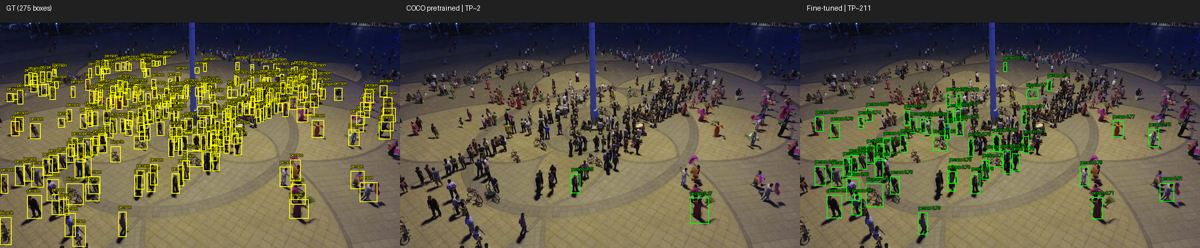

Saved: 02_0000063_00500_d_0000001.jpg
Saved: 03_0000321_00000_d_0000015.jpg
Saved: 04_9999938_00000_d_0000212.jpg
Saved: 05_0000063_12500_d_0000014.jpg
Saved: 06_0000127_00265_d_0000120.jpg


In [6]:
from collections import defaultdict
by_gt=defaultdict(list); by_base=defaultdict(list); by_fine=defaultdict(list)
for a in gt_anns: by_gt[a['image_id']].append(a)
for a in base_dets: by_base[a['image_id']].append(a)
for a in fine_dets: by_fine[a['image_id']].append(a)

def iou_xywh(a,b):
    ax,ay,aw,ah=a; bx,by,bw,bh=b
    w=max(0,min(ax+aw,bx+bw)-max(ax,bx))
    h=max(0,min(ay+ah,by+bh)-max(ay,by))
    z=w*h
    return z/max(aw*ah+bw*bh-z,1e-9)

def illustrative_tp(iid,dets,conf=CONF_VIS):
    gt=by_gt[iid]; taken=set(); tp=0
    for d in sorted((d for d in dets if d['score']>=conf),key=lambda x:-x['score']):
        options=[(iou_xywh(d['bbox'],g['bbox']),j) for j,g in enumerate(gt)
              if j not in taken and g['category_id']==d['category_id']]
        if options:
            v,j=max(options)
            if v>=0.5: taken.add(j); tp+=1
    return tp

rank=[]
for iid in image_ids:
    b=illustrative_tp(iid,by_base[iid]);f=illustrative_tp(iid,by_fine[iid]);
    rank.append((f-b,f,len(by_gt[iid]),iid,b))
rank.sort(reverse=True)
examples=[row[3] for row in rank[:N_EXAMPLES]]
if not examples: raise RuntimeError('Không có ảnh minh họa')

def font(size):
    try: return ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',size)
    except OSError: return ImageFont.load_default()

FONT=font(15);HEADFONT=font(20)

def render_panel(im,anns,title,is_gt=False):
    panel=im.copy().convert('RGB')
    d=ImageDraw.Draw(panel)
    items=anns if is_gt else sorted((a for a in anns if a['score']>=CONF_VIS),key=lambda x:-x['score'])[:50]
    for a in items:
        x,y,w,h=a['bbox']; x2=x+w;y2=y+h
        d.rectangle((x,y,x2,y2),outline='yellow' if is_gt else 'lime',width=2)
        label=COMMON_NAMES[a['category_id']]
        if not is_gt: label+=f" {a['score']:.2f}"
        ty=max(0,y-17)
        d.text((x,ty),label,font=FONT,fill='yellow' if is_gt else 'lime',stroke_width=1,stroke_fill='black')
    # Resize only for visual; metrics use original coords.
    target_w=600; h=max(1,round(panel.height*target_w/panel.width))
    panel=panel.resize((target_w,h),Image.Resampling.LANCZOS)
    header=Image.new('RGB',(target_w,34),'#202020')
    ImageDraw.Draw(header).text((10,6),title,font=HEADFONT,fill='white')
    result=Image.new('RGB',(target_w,h+34),'white')
    result.paste(header,(0,0));result.paste(panel,(0,34))
    return result

VIS_DIR=OUT/'visual_examples';VIS_DIR.mkdir(exist_ok=True)
for j,iid in enumerate(examples,1):
    with Image.open(IMG_PATH[iid]) as raw_im: im=raw_im.copy()
    panels=[render_panel(im,by_gt[iid],f'GT ({len(by_gt[iid])} boxes)',True),
       render_panel(im,by_base[iid],f'COCO pretrained | TP~{illustrative_tp(iid,by_base[iid])}'),
       render_panel(im,by_fine[iid],f'Fine-tuned | TP~{illustrative_tp(iid,by_fine[iid])}')]
    hh=max(p.height for p in panels)
    canvas=Image.new('RGB',(sum(p.width for p in panels),hh),'white')
    xx=0
    for p in panels:
        canvas.paste(p,(xx,0));xx+=p.width
    file=VIS_DIR/f'{j:02d}_{Path(IMG_PATH[iid]).stem}.jpg'
    canvas.save(file,quality=90)
    print('Saved:',file.name)
    if j==1:display(canvas.resize((1200,round(hh*2/3))))

## 6. Đóng gói artifact và thông tin thí nghiệm

ZIP chỉ chứa metrics, dự đoán JSON, hình ảnh, config và metadata; **không đóng gói ảnh raw** hay sao chép trọng số `best.pt` đã có trong Kaggle Dataset.

In [7]:
import hashlib

def checksum(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()

summary={
  'timestamp_utc':datetime.now(timezone.utc).isoformat(),
  'dataset':'tiendq/visdrone-mot-det-converted','split':SPLIT,
  'dataset_root':str(DATASET_ROOT),'annotations':str(ANN_FILE),
  'sample_size':len(chosen),'total_images_in_split':len(all_images),'sample_seed':SEED,
  'pretrained_checkpoint':str(BASE_PT),'best_checkpoint':str(BEST_PT),
  'best_checkpoint_sha256':checksum(BEST_PT),'imgsz':IMGSZ,
  'conf_eval':CONF_EVAL,'conf_visual':CONF_VIS,'iou_nms':IOU_NMS,
  'max_detections_inference':MAX_DET,'max_detections_cocoeval':1000,
  'common_classes':COMMON_NAMES,'gt_mapping':VIS_GT_MAP,
  'excluded_visdrone_class_ids':sorted(VIS_EXCLUDED),
  'ignored_prediction_policy':'Exclude detections with intersection/prediction-area >=0.5 against ignored regions and VisDrone classes 7/8',
  'important_note':'Custom merged-six-class metric, NOT official VisDrone ten-class mAP',
  'metrics':{'pretrained':base_row,'finetuned':fine_row},
  'gpu':torch.cuda.get_device_name(0),'torch':torch.__version__,'ultralytics':ultralytics.__version__,
  'python':platform.python_version(),
}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
(OUT/'selected_images.json').write_text(json.dumps([{'id':i['id'],'file_name':i['file_name']} for i in chosen],indent=2),encoding='utf-8')
ZIP_PATH=WORK/f'{OUT.name}_artifacts.zip'
with zipfile.ZipFile(ZIP_PATH,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4) as zf:
    for f in sorted(OUT.rglob('*')):
        if f.is_file(): zf.write(f,arcname=str(f.relative_to(OUT.parent)))
print('RESULT DIR:',OUT)
print('ZIP:',ZIP_PATH, '| size MB:',round(ZIP_PATH.stat().st_size/1e6,2))
print('Chỉ số chính:')
display(metrics_df[['model','mAP50_95','mAP50','AP_small','img_per_sec']])

RESULT DIR: /kaggle/working/compare_yolo11m_det_test-dev_all
ZIP: /kaggle/working/compare_yolo11m_det_test-dev_all_artifacts.zip | size MB: 37.27
Chỉ số chính:


,model,mAP50_95,mAP50,AP_small,img_per_sec
0,COCO pretrained,0.086070,0.146860,0.028507,19.83
1,VisDrone fine-tuned,0.260547,0.439685,0.130962,24.41
